# 05 · Decaying turbulence in 2D: random fields, spectra, and how far gradients can see

Notebook 06 will ask diffhydro to find a turbulent velocity field that, after a while, *writes a letter* in the
density. This notebook builds the pieces and the intuition for that:

**In this notebook you will:**
- generate **Gaussian random fields** with a chosen power spectrum and measure spectra,
- split velocity fields into **compressive** and **solenoidal** parts (Helmholtz decomposition),
- build a **differentiable turbulent initial condition** from white noise. This is the parametrisation we will optimise in notebook 06,
- run **decaying (unforced) turbulence** with diffhydro and look at energy decay, spectra and the density PDF,
- use forward- and reverse-mode autodiff to see **which parts of the initial condition influence the final state**, and
  how perturbations grow: the practical limit on how long an inverse problem can be.


Decaying turbulence (as well as driven turblence, not covered here but in DiffHydro) is a common model for ISM physics and a nice method to show-off inference problems and makes cool pictures.

In [1]:
import sys, time
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp

try:
    import diffhydro as dh
except ImportError:
    sys.path.insert(0, "../..")
    import diffhydro as dh
import tutorial_utils as tu

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3, "image.interpolation": "nearest"})
print("JAX backend:", jax.default_backend())
N = 128          # grid for the forward experiments (CPU-friendly)
N_GRAD = 64      # smaller grid for the gradient experiments in section 4

JAX backend: cpu


## 1. Gaussian random fields

A statistically homogeneous Gaussian random field is fully described by its **power spectrum** $P(k)$, the variance
per Fourier mode. The recipe is the reparametrisation from notebook 02, in 2D:

1. draw white noise $w(\mathbf x) \sim \mathcal N(0, 1)$ (flat spectrum, independent cells),
2. Fourier transform, multiply by $\sqrt{P(k)}$, transform back.

Because $w$ is real, its transform is Hermitian and the result is real. Spectral slopes control the look:

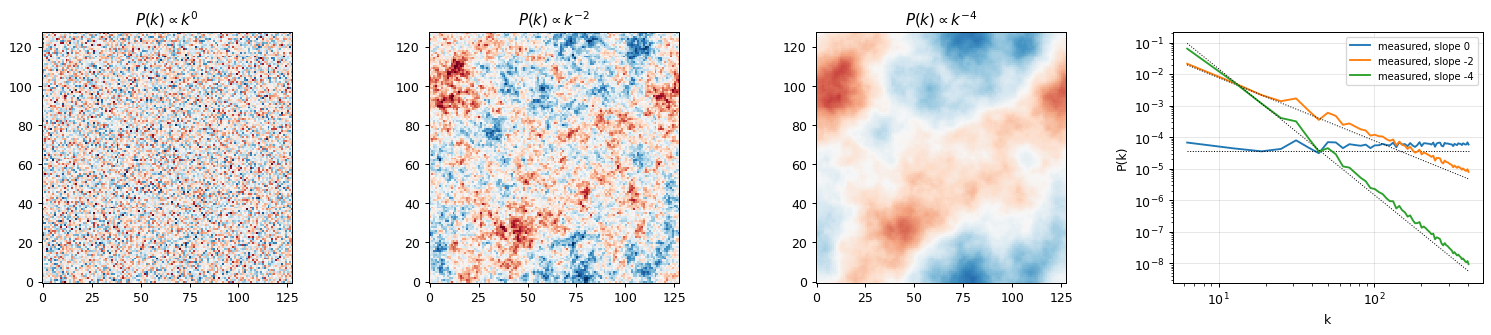

In [2]:
slopes = [0.0, -2.0, -4.0]
fields = [tu.gaussian_random_field_2d(N, lambda k, s=s: k ** s, seed=1) for s in slopes]

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, f, s in zip(axes, fields, slopes):
    ax.imshow(f.T, origin="lower", cmap="RdBu_r", vmin=-3, vmax=3); ax.set_title(f"$P(k) \\propto k^{{{s:g}}}$"); ax.grid(False)
for f, s in zip(fields, slopes):
    k, pk = tu.power_spectrum_2d(f)
    axes[3].loglog(k, pk, label=f"measured, slope {s:g}")
    axes[3].loglog(k, pk[2] * (k / k[2]) ** s, "k:", lw=0.8)
axes[3].set_xlabel("k"); axes[3].set_ylabel("P(k)"); axes[3].legend(fontsize=8)
plt.tight_layout()

The steeper the spectrum, the more the large scales dominate. Measured spectra (azimuthal averages in shells of
$|\mathbf k|$) follow the input slope, with scatter at low $k$ where each shell has only a few modes (**cosmic variance**).

## 2. Turbulent velocity fields: compressive and solenoidal

Any periodic velocity field splits uniquely into a curl-free (**compressive**) part and a divergence-free
(**solenoidal**) part. In 2D both come from scalar fields:

$$\mathbf v = \underbrace{\nabla\phi}_{\nabla\times = 0} + \underbrace{\nabla\times(\psi\,\hat{\mathbf z})}_{\nabla\cdot = 0},
\qquad \nabla\times(\psi\hat{\mathbf z}) = (\partial_y\psi,\ -\partial_x\psi).$$

Compressive motions **converge and diverge**, so they pile up gas and make shocks. Solenoidal motions **swirl**: they
stretch and fold structures without compressing them (much). For notebook 06 this matters: to *write* something in
the density field, the flow has to move gas, and gas only piles up where $\nabla\cdot\mathbf v < 0$.

In Fourier space $\nabla \to i\mathbf k$, so building $\mathbf v$ from two white-noise fields $w_\phi, w_\psi$ is just a
fixed linear filter. That is `tu.make_turbulent_ic`, written here in full:

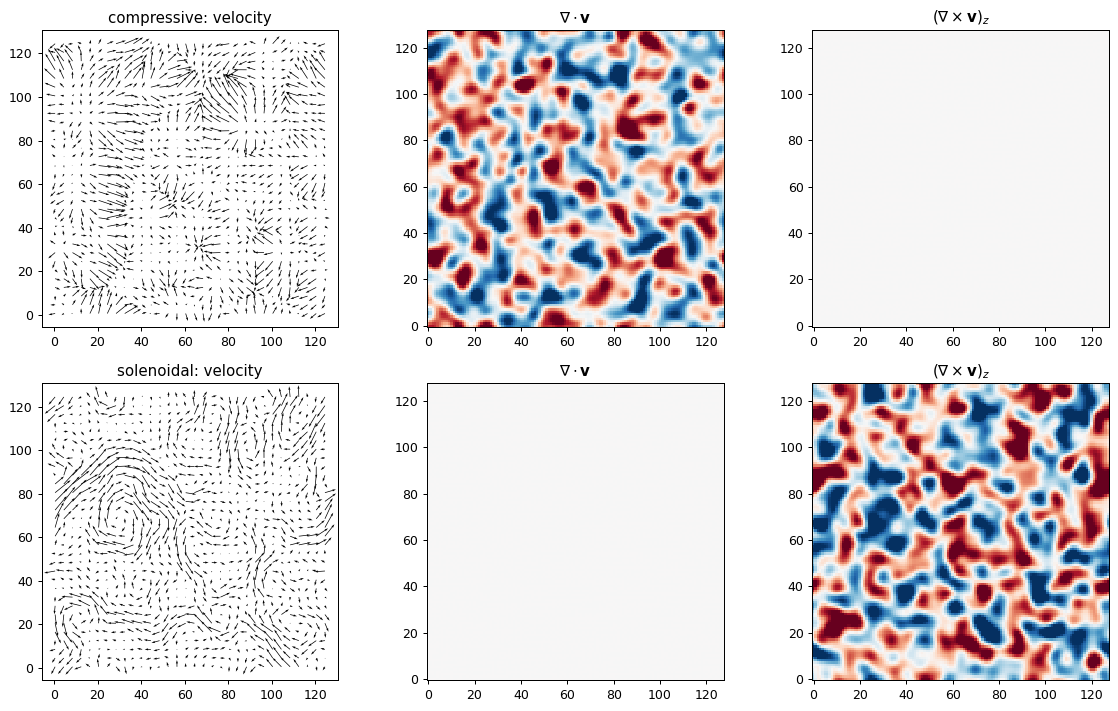

In [3]:
def make_turbulent_ic(n, mach=1.0, kcut=8.0, pslope=-2.0, solenoidal_fraction=0.5, gamma=5 / 3):
    kx, ky = tu.k_grid_2d(n)
    k = np.sqrt(kx ** 2 + ky ** 2)
    kint = k / (2 * np.pi)                                        # wavenumber in units of the box
    nz = k > 0
    amp = np.where(nz, np.where(nz, kint, 1.0) ** (pslope / 2) * np.exp(-0.5 * (kint / kcut) ** 2), 0.0)
    inv_k = np.where(nz, 1.0 / np.where(nz, k, 1.0), 0.0)        # 1/k with k = 0 removed (numpy, never traced)
    gx, gy = 1j * kx * inv_k * amp, 1j * ky * inv_k * amp          # i k/|k| sqrt(P): gradient of a field with spectrum P/k^2
    norm = np.sqrt(np.mean(np.abs(gx) ** 2 + np.abs(gy) ** 2))      # unit-variance w -> unit rms |v|
    gx, gy = jnp.asarray((gx / norm).astype(np.complex64)), jnp.asarray((gy / norm).astype(np.complex64))
    fc, fs = np.sqrt(1.0 - solenoidal_fraction), np.sqrt(solenoidal_fraction)
    p0 = 1.0 / gamma                                              # rho = 1, p = 1/gamma  ->  sound speed 1

    def ic(w):
        wc, ws = jnp.fft.fft2(w[0]), jnp.fft.fft2(w[1])
        vx = mach * jnp.fft.ifft2(fc * gx * wc + fs * gy * ws).real   # d(phi)/dx + d(psi)/dy
        vy = mach * jnp.fft.ifft2(fc * gy * wc - fs * gx * ws).real   # d(phi)/dy - d(psi)/dx
        one = jnp.ones((n, n), vx.dtype)
        return jnp.stack([one, vx, vy, 0.0 * vx, p0 * one])[..., None]   # primitives (rho, vx, vy, vz, p)

    return ic

w0 = jnp.asarray(np.random.default_rng(0).standard_normal((2, N, N)), jnp.float32)
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for row, sf, name in zip(axes, (0.0, 1.0), ("compressive", "solenoidal")):
    W = make_turbulent_ic(N, solenoidal_fraction=sf)(w0)
    vx, vy = np.asarray(W[1, ..., 0]), np.asarray(W[2, ..., 0])
    div, curl = tu.div_curl_2d(vx, vy)
    s = 4
    c = np.arange(0, N, s) + 0.5
    row[0].quiver(c, c, vx[::s, ::s].T, vy[::s, ::s].T, scale=30); row[0].set_aspect("equal"); row[0].set_title(f"{name}: velocity")
    lim = np.abs(div).max() + np.abs(curl).max()
    row[1].imshow(div.T, origin="lower", cmap="RdBu_r", vmin=-lim / 2, vmax=lim / 2); row[1].set_title(r"$\nabla\cdot\mathbf{v}$")
    row[2].imshow(curl.T, origin="lower", cmap="RdBu_r", vmin=-lim / 2, vmax=lim / 2); row[2].set_title(r"$(\nabla\times\mathbf{v})_z$")
    for ax in row: ax.grid(False)
plt.tight_layout()

Same white noise, two very different flows: the compressive field has no vorticity and the solenoidal field has no
divergence. The rms Mach number of either is set by `mach`, and `kcut` sets the size of the largest eddies' smaller cousins
(the spectrum is cut off exponentially above `kcut`).

diffhydro also ships a ready-made generator, `dh.turbulence.init_turbulent_velocity(eq, Lbox, rho0, p0, kmin, kmax,
solenoidal_frac, pslope, target_M, seed)`, which returns a conservative state directly (3D or 2D with `mesh_shape=[n, n, 1]`).
It draws its own random numbers from a seed, though, while ours takes the white noise $w$ as an *input*, which is exactly
what we need to optimise it.

## 3. Decaying turbulence with diffhydro

Let's set the flow loose with no forcing. Kinetic energy cascades and decays, shocks form where compressive flows
collide, and density fluctuations develop. We compare a subsonic (Mach 0.5) and a supersonic (Mach 2) run, half
solenoidal and half compressive, with the 2D helper `tu.make_hydro` (the `make_sim` of notebook 04, with HLLC + MUSCL3 + RK2).

In [4]:
gamma = 5 / 3
times = [0.0, 0.03, 0.08, 0.2, 0.6]
runs = {}
for mach in (0.5, 2.0):
    eq, sim = tu.make_hydro(N, N, gamma=gamma)
    U = eq.get_conservatives_from_primitives(make_turbulent_ic(N, mach=mach, gamma=gamma)(w0))
    snaps = [np.asarray(eq.get_primitives_from_conservatives(U)[..., 0])]
    t_now, t0 = 0.0, time.perf_counter()
    for t_target in times[1:]:
        U, _, dt_run, _, _ = sim.evolve_till_time(U, {}, t_target - t_now)
        t_now += float(dt_run)
        snaps.append(np.asarray(eq.get_primitives_from_conservatives(U)[..., 0]))
    runs[mach] = np.array(snaps)          # (n_times, 5, N, N) primitives
    print(f"Mach {mach}: evolved to t = {t_now:.2f} in {time.perf_counter() - t0:.1f} s")

Mach 0.5: evolved to t = 0.60 in 10.9 s


Mach 2.0: evolved to t = 0.60 in 13.6 s


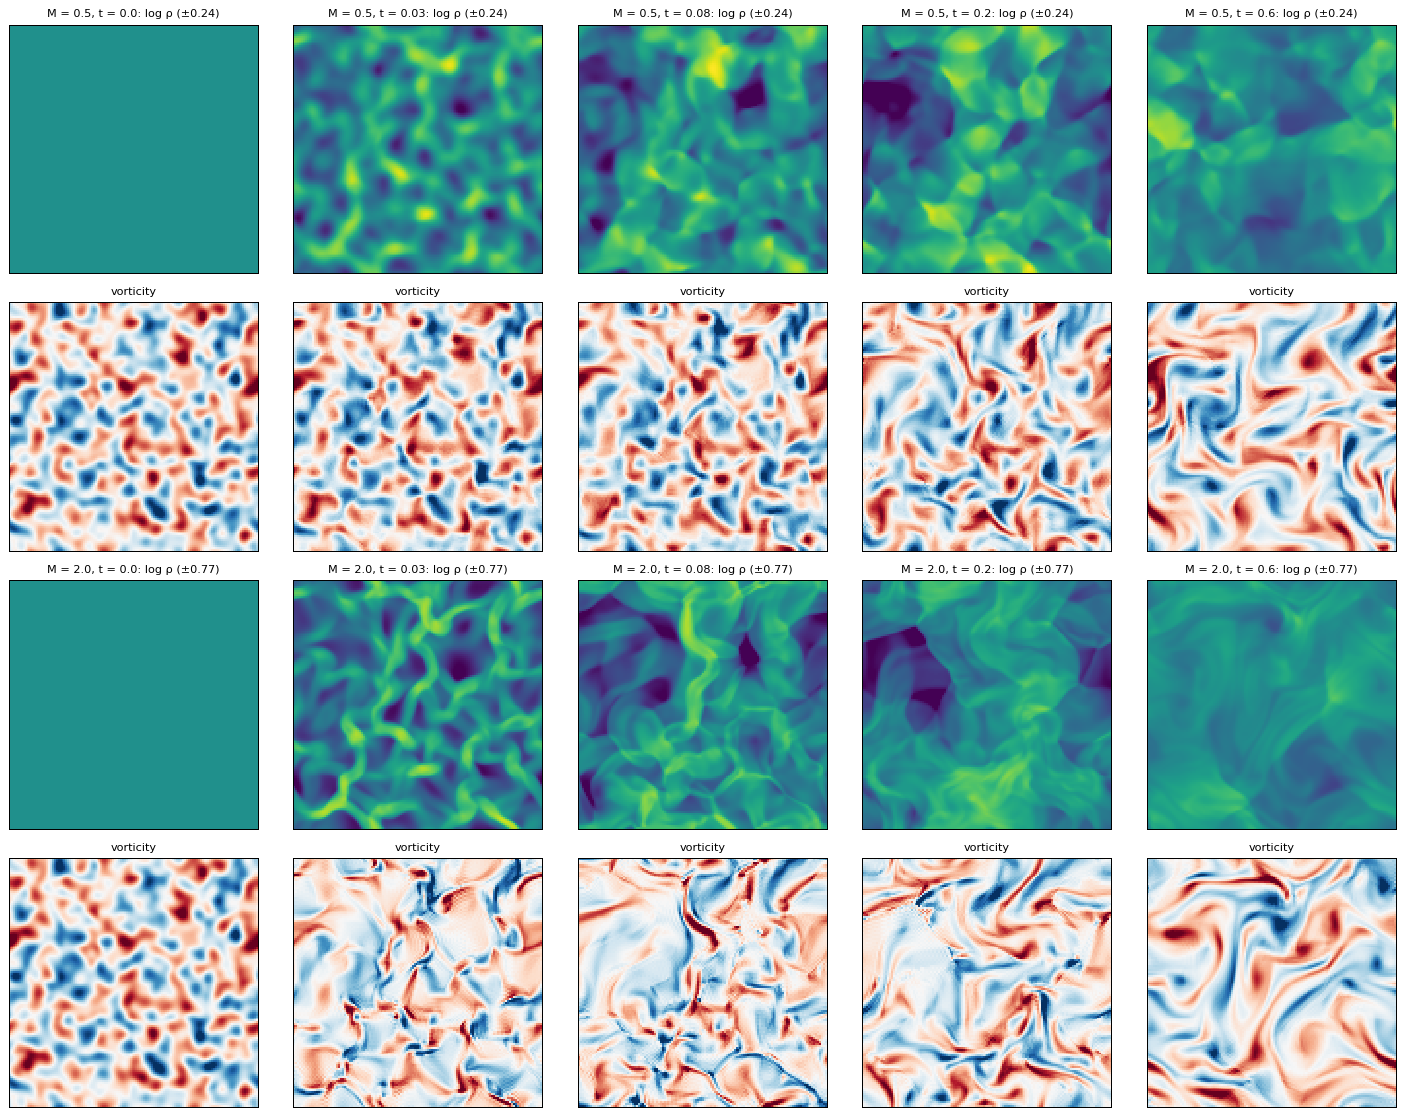

In [5]:
fig, axes = plt.subplots(4, len(times), figsize=(3.2 * len(times), 12.5))
for r, mach in enumerate((0.5, 2.0)):
    lim_rho = np.percentile(np.abs(np.log10(runs[mach][:, 0])), 99.5)      # one colour scale per Mach number
    for c, t in enumerate(times):
        W = runs[mach][c]
        _, vort = tu.div_curl_2d(W[1], W[2])
        ax = axes[2 * r, c]
        ax.imshow(np.log10(W[0]).T, origin="lower", cmap="viridis", vmin=-lim_rho, vmax=lim_rho)
        ax.set_title(f"M = {mach}, t = {t}: log ρ (±{lim_rho:.2f})", fontsize=9)
        lim = np.percentile(np.abs(vort), 99)
        axes[2 * r + 1, c].imshow(vort.T, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim)
        axes[2 * r + 1, c].set_title("vorticity", fontsize=9)
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout()

The time unit is the sound-crossing time of the box ($c_s = 1$, $L = 1$).

* At **Mach 0.5** density fluctuations stay modest (tens of per cent, $\delta\rho/\rho \sim \mathcal M^2$): the flow behaves
  like nearly incompressible 2D turbulence, and vortices slowly merge into larger ones (the **inverse cascade** of 2D turbulence).
* At **Mach 2** colliding streams make **shocks** within a few hundredths of a crossing time: thin, dense filaments
  next to rarefied voids. But this gas is *adiabatic* ($\gamma = 5/3$). Shocks convert kinetic energy into heat, the
  sound speed rises, the flow quickly becomes subsonic, and by $t = 0.6$ the contrast has largely washed out again.
  (Isothermal gas, which radiates the heat away, would keep its filaments.)

Let's quantify energy decay, spectra and the density PDF.

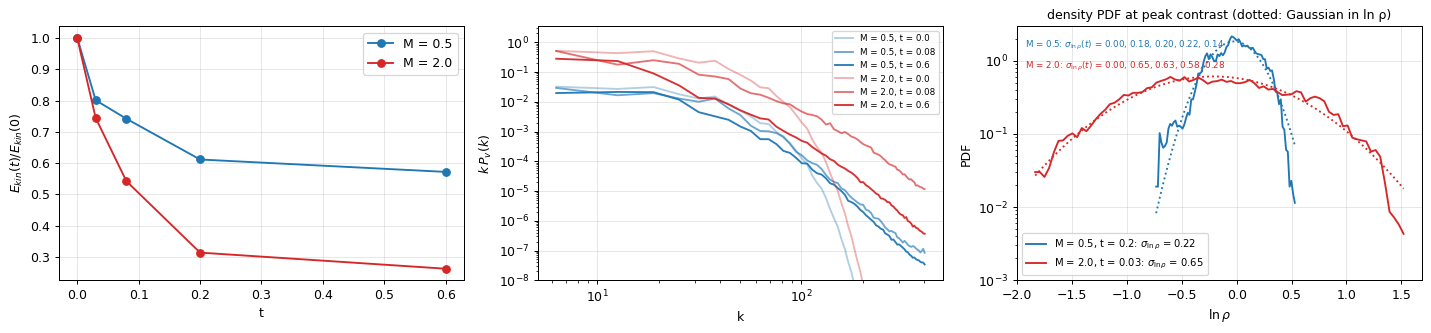

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for mach, col in ((0.5, "C0"), (2.0, "C3")):
    W = runs[mach]
    ekin = 0.5 * np.mean(W[:, 0] * (W[:, 1] ** 2 + W[:, 2] ** 2), axis=(1, 2))
    axes[0].plot(times, ekin / ekin[0], "o-", color=col, label=f"M = {mach}")
    for i, t in enumerate(times[::2]):
        Wt = W[2 * i]
        k, ex = tu.power_spectrum_2d(Wt[1]); _, ey = tu.power_spectrum_2d(Wt[2])
        axes[1].loglog(k, (ex + ey) * k, color=col, alpha=0.35 + 0.3 * i, label=f"M = {mach}, t = {t}")
    sig_t = np.log(W[:, 0]).reshape(len(times), -1).std(axis=1)
    i_peak = int(np.argmax(sig_t))
    lnrho = np.log(W[i_peak, 0]).ravel()
    hist, edges = np.histogram(lnrho, bins=80, density=True)
    cen = 0.5 * (edges[1:] + edges[:-1])
    axes[2].semilogy(cen, hist, color=col, label=rf"M = {mach}, t = {times[i_peak]}: $\sigma_{{\ln\rho}}$ = {lnrho.std():.2f}")
    axes[2].text(0.02, 0.95 - 0.08 * (mach > 1), rf"M = {mach}: $\sigma_{{\ln\rho}}(t)$ = " + ", ".join(f"{v:.2f}" for v in sig_t),
                 transform=axes[2].transAxes, fontsize=7, color=col, va="top")
    axes[2].semilogy(cen, np.exp(-0.5 * ((cen - lnrho.mean()) / lnrho.std()) ** 2) / (np.sqrt(2 * np.pi) * lnrho.std()),
                     ":", color=col)
axes[0].set_xlabel("t"); axes[0].set_ylabel(r"$E_{kin}(t)/E_{kin}(0)$"); axes[0].legend()
axes[1].set_xlabel("k"); axes[1].set_ylabel(r"$k\,P_v(k)$"); axes[1].set_ylim(1e-8, None); axes[1].legend(fontsize=7)
axes[2].set_xlabel(r"$\ln\rho$"); axes[2].set_ylabel("PDF"); axes[2].set_ylim(1e-3, None); axes[2].legend(fontsize=8)
axes[2].set_title("density PDF at peak contrast (dotted: Gaussian in ln ρ)", fontsize=10)
plt.tight_layout()

* **Energy decay**: supersonic turbulence loses most of its kinetic energy within a tenth of a crossing time, because
  shocks dissipate it into heat. The subsonic run first loses its compressive (acoustic) part, then decays slowly.
* **Spectra**: energy moves from the injection band ($k \lesssim$ `kcut` $= 8$) to both larger and smaller scales;
  at high $k$ the spectra fall off where numerical dissipation takes over (a few cells).
* **Density PDF**: close to **lognormal** (a Gaussian in $\ln\rho$) because successive compressions and expansions
  multiply, so their logarithms add up. Its width grows with the Mach number; for isothermal turbulence
  $\sigma^2_{\ln\rho} \approx \ln(1 + b^2\mathcal M^2)$ with $b \approx 1/3$–$1$ depending on the forcing. The numbers in the
  panel show how fast the width peaks and then decays in our adiabatic runs.

## 4. What does the final state remember? Gradients and chaos

For the inverse problem of notebook 06 two questions matter:

1. **Which parts of the initial condition can influence a given patch of the final density?** If the answer is "only a
   small neighbourhood", the gradient of a loss on that patch is *local* and the optimiser has little freedom.
2. **How sensitive is the final state to small changes in the initial one?** If perturbations grow exponentially
   (**chaos**), gradients through long runs explode and become useless.

We answer the first with **reverse mode**: the gradient of the mean density in a small square at time $T$ with respect to
both white-noise channels $w$ of the IC, for increasing $T$. We use `evolve_with_dt_schedule` with a fixed time step so that
$T$ is exact, and a smaller grid to keep CPU time reasonable.

T = 0.02: gradient in 18.2 s


T = 0.08: gradient in 15.2 s


T = 0.2: gradient in 24.0 s


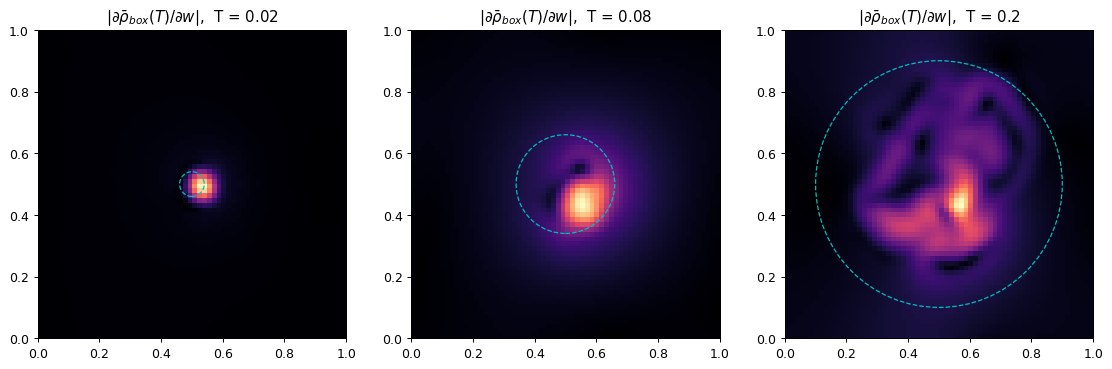

In [7]:
n = N_GRAD
mach = 1.0
eqg, simg = tu.make_hydro(n, n, gamma=gamma)
ic_g = tu.make_turbulent_ic(n, mach=mach, gamma=gamma)
w_g = jnp.asarray(np.random.default_rng(3).standard_normal((2, n, n)), jnp.float32)
dt_fixed = 0.3 / n / (1 + 3 * mach)            # safe CFL for flows up to ~3x the rms Mach number

def rho_at(w, T):
    n_steps = int(round(T / dt_fixed))
    U0 = eqg.get_conservatives_from_primitives(ic_g(w))
    U, _, _ = simg.evolve_with_dt_schedule(U0, {}, jnp.full((n_steps,), T / n_steps))
    return U[0, :, :, 0]

box = (slice(n // 2 - 2, n // 2 + 2), slice(n // 2 - 2, n // 2 + 2))     # a 4x4-cell patch in the centre
horizons = [0.02, 0.08, 0.2]
sens = []
for T in horizons:
    t0 = time.perf_counter()
    g = jax.grad(lambda w: jnp.mean(rho_at(w, T)[box]))(w_g)
    sens.append(np.asarray(jnp.sqrt(g[0] ** 2 + g[1] ** 2)))
    print(f"T = {T}: gradient in {time.perf_counter() - t0:.1f} s")

fig, axes = plt.subplots(1, len(horizons), figsize=(4.2 * len(horizons), 4))
ext = [0, 1, 0, 1]
for ax, s, T in zip(axes, sens, horizons):
    ax.imshow(s.T, origin="lower", cmap="magma", extent=ext)
    ax.add_patch(plt.Circle((0.5, 0.5), T * (1 + mach), fill=False, color="c", ls="--", lw=1))
    ax.set_title(rf"$|\partial \bar\rho_{{box}}(T) / \partial w|$,  T = {T}"); ax.grid(False)
plt.tight_layout()

The sensitivity is centred on the target patch and spreads with time. The dashed circle has radius
$(c_s + v_\mathrm{rms})\,T$, roughly the distance information can travel by sound waves plus advection.
The sensitivity map is also smooth, because $w$ enters through the band-limited filter of `make_turbulent_ic`: the
optimiser can only change the IC by smooth, large-scale velocity patterns, which is the regularisation we want.

Now the second question. **Forward mode** is ideal for tracking how *one* perturbation evolves: push a tangent
$\delta w$ through the simulation with `jax.jvp` and record the size of the density response, chunk by chunk.

Mach 0.5: 17.9 s


Mach 2.0: 33.4 s


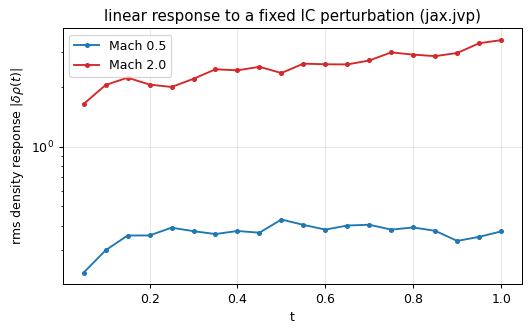

In [8]:
def growth_curve(mach, w, dw, T_total=1.0, n_chunks=20):
    # rms density response to an IC perturbation dw, pushed through the run chunk by chunk with jax.jvp
    ic = tu.make_turbulent_ic(n, mach=mach, gamma=gamma)
    steps = int(round(T_total / n_chunks * n * (1 + 3 * mach) / 0.3))      # same CFL safety as above
    dts = jnp.full((steps,), T_total / n_chunks / steps)
    chunk = lambda U: simg.evolve_with_dt_schedule(U, {}, dts)[0]
    jvp_chunk = jax.jit(lambda U, dU: jax.jvp(chunk, (U,), (dU,)))
    U, dU = jax.jvp(lambda w: eqg.get_conservatives_from_primitives(ic(w)), (w,), (dw,))
    out = []
    for _ in range(n_chunks):
        U, dU = jvp_chunk(U, dU)
        out.append(float(jnp.sqrt(jnp.mean(dU[0] ** 2))))
    return np.linspace(0, T_total, n_chunks + 1)[1:], np.array(out)

dw = jnp.asarray(np.random.default_rng(7).standard_normal((2, n, n)), jnp.float32)
fig, ax = plt.subplots(figsize=(6, 3.8))
for m, col in ((0.5, "C0"), (2.0, "C3")):
    t0 = time.perf_counter()
    tt, resp = growth_curve(m, w_g, dw)
    print(f"Mach {m}: {time.perf_counter() - t0:.1f} s")
    ax.semilogy(tt, resp, "o-", ms=3, color=col, label=f"Mach {m}")
ax.set_xlabel("t"); ax.set_ylabel(r"rms density response $|\delta\rho(t)|$")
ax.set_title("linear response to a fixed IC perturbation (jax.jvp)"); ax.legend()
plt.tight_layout()

The density response jumps up early, as converging flows turn the velocity perturbation into density perturbations.
After that it keeps **growing** in the supersonic run, about 3× over one crossing time, while it saturates in the subsonic run.
This is a mild version of chaos: our flow is decaying and numerically viscous, and at $64^2$ it has little room for small-scale
structure. In driven, high-Reynolds-number (and 3D) turbulence the growth is exponential (positive Lyapunov exponents), and
gradients through long runs become huge and erratic. **The longer the horizon, the less useful the gradient**, and
the gentler the inverse problem has to be.

For notebook 06 this suggests a **moderate horizon**: long enough that the flow has to genuinely *build* the letter from
uniform gas (a few eddy turnover times of the IC's smallest eddies, $\sim 1/(k_\mathrm{cut}\,v_\mathrm{rms})$),
short enough that gradients stay informative. We will use $T = 0.25$ at Mach 1.

## Summary and what's next

* Gaussian random fields = white noise × $\sqrt{P(k)}$. Velocity fields = $\nabla\phi + \nabla\times\psi$; compressive flows pile up gas.
* `make_turbulent_ic(w)` is a **linear, differentiable map** from white noise to a turbulent initial condition, with
  a built-in smoothness prior (band limit `kcut`) and natural scale (unit-variance $w$ gives Mach `mach`).
* Decaying supersonic turbulence makes shocks, filaments and a lognormal density PDF within a fraction of a crossing time.
* Reverse mode shows the **domain of influence** of a patch; forward mode shows how **perturbations grow** in time.

**Notebook 06** puts it all together: start from uniform gas with a *random* turbulent velocity field and let
Adam reshape the white noise $w$, through 400+ steps of diffhydro, until at $t = T$ the gas has piled up into a letter.